# **PROJETO BIAAF - Health Insurance**

### **Projeto desenvolvido por:**
- Débora Jesus, nº2250064
- João Vasques, nº2250055
- Rui Filipe Parada, nº2211025

---

O objetivo deste caso de estudo é fazer uma previsão para companhias de seguro de saúde com base em *features* como a idade, o sexo, índice de massa corporal (IMC, ou é inglês, BMI), número de filhos, se é fumador ou não e a localização geográfica.



| _Feature_ | _Descrição_ |
| :--- | :--- |
| _age_ | Idade do beneficiário |
| _sex_ | Sexo do beneficiário |
| _bmi_ | Índice de massa corporal (idealmente 18.5 a 24.9) |
| _children_ | Número de filhos cobertos pelo seguro de saúde / Número de dependentes |
| _smoker_ | Fumante ou não fumante |
| _region_ | Área residencial do beneficiário nos Estados Unidos da América, nordeste, sudeste, sudoeste e noroeste |
| _charges_ | Custo do seguro de saúde cobrado ao beneficiário (target) |

---


# **1. Business Understanding**

O mercado alvo de análise trata-se do mercado de Seguros de Saúde dos Estados Unidos da América. Conhecido pelos elevados prémios, trata-se de um mercado marioritariamente privado, bastante concentrado por região. Segundo a American Medical Association confirma-se que nas maiores zonas metropolitanas existem duas grandes organizações que dominam o mercado e nas restantes pelo menos uma das seguradoras controla 50% do mercado regional. Dado que o nível de concorrência do mercado é diferente consoante a região e os preços dependem da quota de mercado da empresa, a região torna-se uma *feature* relevante.

Relativamente ao sexo do consumidor, os valores variam com base em dados estatísticos. Segundo a Delloite, as mulheres, em média, utilizam mais cuidados preventivos e consultas de rotina, especialmente entre os 18-40 anos, enquando os homens procuram em idades mais avançadas, são relevantes ainda dados históricos como maiores níveis de tabagismo, maior probabilidade de doenças cardiovascualres em idades mais jovens, maior envolvimento com atividades de risco e mortalidade prematura. Um dado estatístico associado a preços mais elevados para as mulheres baseia-se na maior longevidade, ou seja, em caso de doenças crónicas, existe a necessidade de recorrer mais vezes seguro durante mais anos. Contudo, apesar de ser uma variável relevante para a análise de risco as seguradoras foram reguladas para não poderem cobrar prémios diferentes com base no sexo no mercado individual (Affordable Care Act (ACA)).

Nos Estados Unidos, o IMC é uma métrica central na avaliação de risco em seguros de saúde. Segundo dados do NHANES (National Health and Nutrition Examination Survey), mais de 42% dos adultos apresentam obesidade e 30.7% têm excesso de peso, valores que aumentam significativamente o risco de doenças crónicas e a utilização de cuidados médicos. O CDC (Centers for Disease Control and Prevention) confirma que todos os estados apresentam prevalência de obesidade superior a 20%, com picos acima de 40% em vários estados do Sul e do Midwest. Estes fatores tornam o IMC uma variável determinante na previsão de medical charges e, consequentemente, no cálculo dos prémios, mesmo num contexto regulatório onde a discriminação direta por condições pré‑existentes é proibida pela Affordable Care Act.

Nos Estados Unidos, o tabagismo continua a ser um dos fatores de risco mais penalizados no cálculo dos prémios de seguros de saúde, devido ao seu impacto direto na morbilidade e nos custos médicos. Segundo o CDC, cerca de 10–12% dos adultos norte‑americanos fumam cigarros, de acordo com os dados mais recentes do NHIS (National Health Interview Survey). O tabagismo está associado a doenças cardiovasculares, respiratórias e oncológicas, aumentando a utilização de cuidados médicos e os custos anuais por segurado. Por este motivo, a Affordable Care Act permite a aplicação de um *smoker surcharge*, que pode elevar o prémio até 50% consoante o estado. Assim, a variável *smoker* é altamente relevante na previsão de medical charges, refletindo um comportamento de risco com impacto direto e regulamentado n

Por fim, embora se possa argumentar que ter filhos está associado a estilos de vida menos arriscados, este fator não reduz o prémio no contexto dos seguros de saúde norte‑americanos. O número de dependentes é tratado pelas seguradoras como um aumento direto do risco agregado, uma vez que cada dependente adicional representa um potencial utilizador dos serviços de saúde. Assim, mais dependentes traduzem‑se em maior custo esperado para a seguradora, tornando a variável children relevante na previsão de medical charges.


**Questões analíticas:**

- Qual é o impacto financeiro médio do hábito de fumar nos custos totais?
- De que forma ter ou não ter filhos influencia o valor do seguro de saúde?
- Qual a diferença de serviço prestado aos beneficiários dependendo da região geográfica nos Estados Unidos?

# **2. Imports and Data Upload**

In [1]:
%pip install matplotlib seaborn scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.


In [2]:
# =========================
# STANDARD LIBRARY
# =========================
import os
import io
import warnings
import zipfile

warnings.filterwarnings("ignore")

# =========================
# DATA HANDLING
# =========================
import pandas as pd
import numpy as np
from scipy.io import arff

# =========================
# VISUALIZATION
# =========================
import matplotlib.pyplot as plt
import seaborn as sns

# =========================
# MACHINE LEARNING - SKLEARN
# =========================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# =========================
# CLOUD / MLOPS (AWS / SAGEMAKER)
# =========================
import boto3
import sagemaker
from sagemaker.image_uris import retrieve
from sagemaker.sklearn.model import SKLearnModel

# =========================
# OPTIONAL (COLAB ONLY)
# =========================
# from google.colab import drive
# from google.colab import files

# =========================
# EXTRA UTILITIES
# =========================
import requests
import joblib

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml


In [3]:
# Upload do dataset (em csv)

df = pd.read_csv('insurance.csv', sep=',')

# **3. Análise Exploratória dos Dados**


## **3.1. Análise do Dataset**

In [4]:
# Visualizar as 10 primeiras linhas do novo DataFrame review_df
display(df.head(10))

# Mostrar informação estrutural do DataFrame
print("--------------------------------")
print("Colunas do DataFrame:", list(df.columns))
print("--------------------------------")
print("Número total de registos:", len(df))

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


--------------------------------
Colunas do DataFrame: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
--------------------------------
Número total de registos: 1338


In [5]:
### ---ANÁLISE DO DATASET--- ###

print("----- ANÁLISE DO DATASET -----\n")

# Forma do dataset
print("----- Forma do dataset -----\n")
print(f"df shape:   {df.shape}\n")

print("----- Informações do dataset -----\n")
print(f" df info:   {df.info()}\n")

# Tipos de dados
print("----- Tipo de dados do dataset -----\n")
print("df dtypes:")
print(df.dtypes, "\n")

# Estatísticas descritivas
print("----- Dados descritivos do dataset -----\n")
print("df describe:")
print(df.describe(), "\n")

# Duplicados
print("----- Duplicados do dataset -----\n")
print(f"df duplicados:   {df.duplicated().sum()}\n")

# Nulos por coluna
print("----- Nulos por coluna -----\n")
print("df nulos por coluna:")
print(df.isnull().sum(), "\n")

# Total de nulos
print("----- Total de nulos -----\n")
print(f"df total de nulos:   {df.isnull().sum().sum()}")

----- ANÁLISE DO DATASET -----

----- Forma do dataset -----

df shape:   (1338, 7)

----- Informações do dataset -----

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
 df info:   None

----- Tipo de dados do dataset -----

df dtypes:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object 

----- Dados descritivos do dataset -----

df describe:
               age          bmi     children       charges
count  1338.000000  13

A análise inicial revela que o dataset é composto por **1.338 observações e 7 variáveis**: `'age'` (idade do beneficiário), `'sex'` (género), `'bmi'` (índice de massa corporal), `'children'` (número de filhos/dependentes), `'smoker'` (se é fumador ou não), `'region'` (região residencial nos EUA) e `'charges'` (custo do seguro de saúde, que constitui a nossa variável *target*).

Relativamente aos tipos de dados, as variáveis categóricas (`'sex'`, `'smoker'`, `'region'`) estão definidas como **object**, enquanto as variáveis numéricas dividem-se entre **int64** (`'age'`, `'children'`) e **float64** (`'bmi'`, `'charges'`). Consideramos esta configuração adequada para as fases subsequentes de análise e modelação.

No que respeita à **integridade dos dados**, não detetamos valores nulos em nenhuma das colunas, garantindo que o dataset está totalmente preenchido. Contudo,
identificámos a presença de **1 registo duplicado** que deverá ser alvo de atenção - possivelmente removido, já que *rows* duplicadas não acrescentam informação relevante para o modelo.

A **análise estatística** das variáveis numéricas mostra que a idade média dos indivíduos é de aproximadamente 39 anos, com uma amplitude que vai dos 18 aos 64 anos. O IMC (`'bmi'`) médio situa-se nos 30,66, valor que se encontra acima do intervalo considerado ideal (18,5 a 24,9), sugerindo uma prevalência de excesso de peso na amostra. Quanto aos custos (`'charges'`), o valor médio é de cerca de 13.270,42, embora a mediana seja significativamente inferior (9.382,03), o que indica uma distribuição possivelmente influenciada por valores elevados de tratamentos específicos, atingindo um máximo de 63.770,43.

## **3.2. Análise por coluna**

Com o intuito de aprofundar o nosso conhecimento sobre cada uma das variáveis que compõem o dataset, decidimos desenvolver uma análise individual sobre cada coluna. Procedemos a este estudo tanto em termos descritivos quanto gráficos, incluindo gráficos de barras, circulares, histogramas (com kde) e boxplots. Esta análise permite aprofundar o nosso conhecimento analítico das features, bem como avaliar a eventual necessidade de tratamento de dados, por exemplo, tratamento de outliers.

### 3.2.1. `'age'`

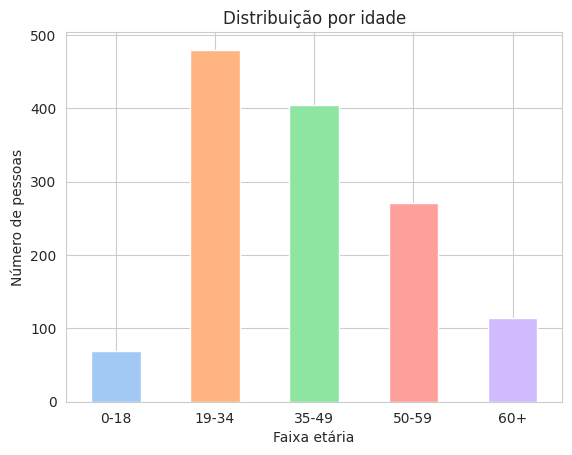

In [6]:
bins = [0, 19, 35, 50, 60, 120]
labels = ['0-18', '19-34', '35-49', '50-59', '60+']

colors = sns.color_palette("pastel")

counts = pd.cut(df['age'], bins=bins, labels=labels, right=False) \
            .value_counts() \
            .sort_index()

sns.set_style("whitegrid")

counts.plot(kind='bar', color=colors)

plt.xlabel('Faixa etária')
plt.ylabel('Número de pessoas')
plt.title('Distribuição por idade')
plt.xticks(rotation=0)

plt.show()

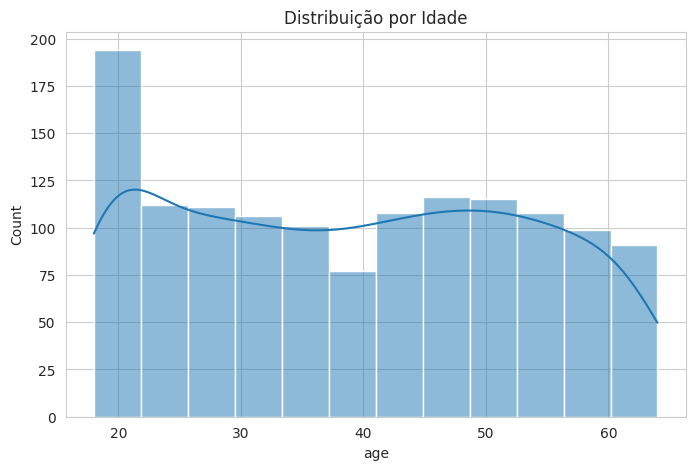

In [7]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='age', kde=True, palette=colors)
plt.title('Distribuição por Idade')
plt.show()

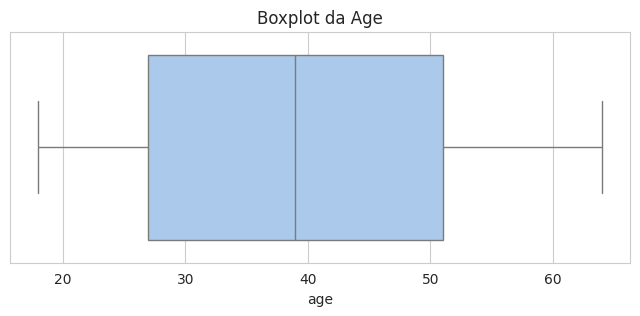

In [8]:
plt.figure(figsize=(8,3))
sns.boxplot(data=df, x='age', palette=colors)
plt.title('Boxplot da Age')
plt.show()

A distribuição etária mostra uma amostra relativamente equilibrada entre os 18 e os 64 anos, com uma **concentração ligeiramente superior na faixa dos jovens adultos (18-20 anos)**, como visível no pico inicial do histograma. Agrupando por faixas etárias, as categorias entre os 19 e os 49 anos são as mais representativas, totalizando a maioria dos beneficiários, enquanto a presença de indivíduos com mais de 60 anos é a mais reduzida na amostra.

### 3.2.2. `'sex'`

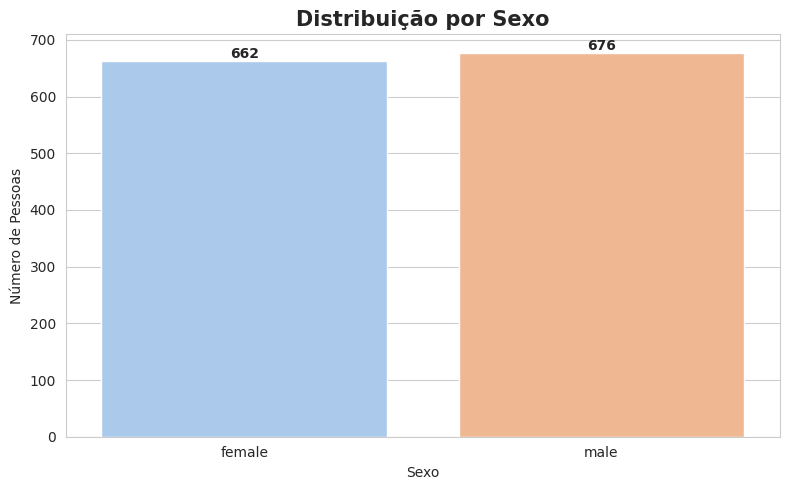

In [9]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='sex',
    hue='sex',
    palette=colors,
    legend=False)

plt.title('Distribuição por Sexo', fontsize=15, fontweight='bold')
plt.ylabel('Número de Pessoas')
plt.xlabel('Sexo')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height)}',
                (p.get_x() + p.get_width() / 2, height),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

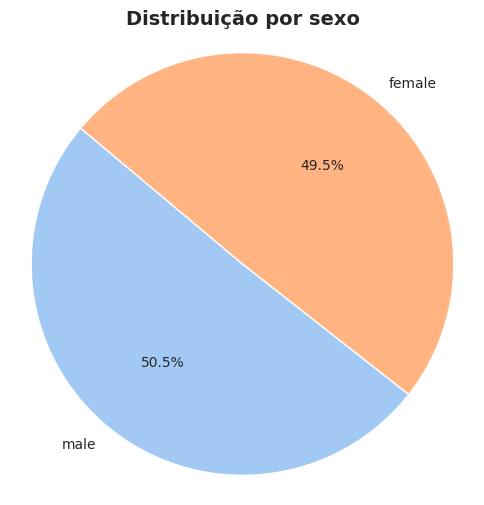

In [10]:
sex_counts = df['sex'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    sex_counts,
    labels=sex_counts.index,
    colors=colors,
    autopct='%1.1f%%',
    startangle=140)

plt.title('Distribuição por sexo', fontsize=14, fontweight='bold')
plt.axis('equal')
plt.show()

A variável de género apresenta uma **distribuição extremamente equilibrada**, quase atingindo a paridade perfeita. O dataset conta com 676 homens (50,5%) e 662 mulheres (49,5%), o que garante que os modelos de previsão não serão enviesados por uma predominância significativa de um dos sexos.

### 3.2.3. `'bmi'`

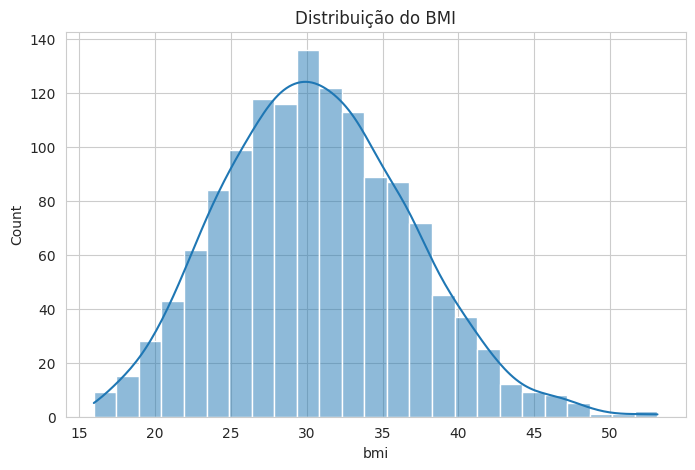

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='bmi', kde=True, palette=colors)
plt.title('Distribuição do BMI')
plt.show()

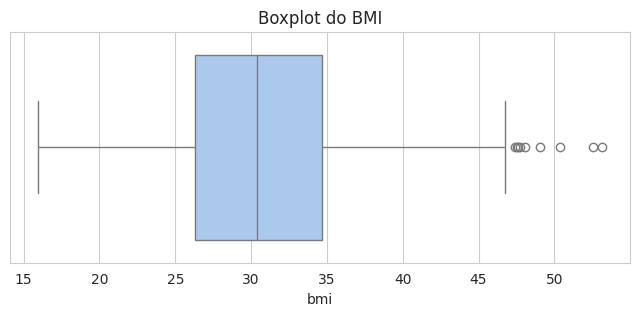

In [12]:
plt.figure(figsize=(8,3))
sns.boxplot(data=df, x='bmi', palette=colors)
plt.title('Boxplot do BMI')
plt.show()

O BMI apresenta uma **distribuição aproximadamente normal**, centrada em torno da média de 30,66. No entanto, a análise do boxplot revela a presença de alguns **valores atípicos (*outliers*) no limite superior**, com indivíduos a apresentarem um IMC acima de 45. É relevante notar que a grande maioria da amostra se encontra acima do intervalo considerado ideal (18,5 a 24,9), situando-se em níveis de excesso de peso ou obesidade.

### 3.2.4. `'children'`

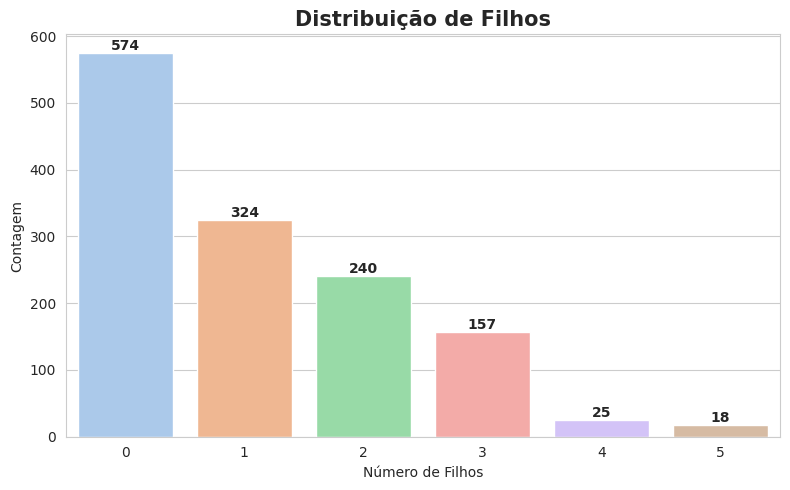

In [13]:
colors = sns.color_palette("pastel")

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='children',
    palette=colors)

plt.title('Distribuição de Filhos', fontsize=15, fontweight='bold')
plt.xlabel('Número de Filhos')
plt.ylabel('Contagem')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height)}',
                (p.get_x() + p.get_width()/2, height),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

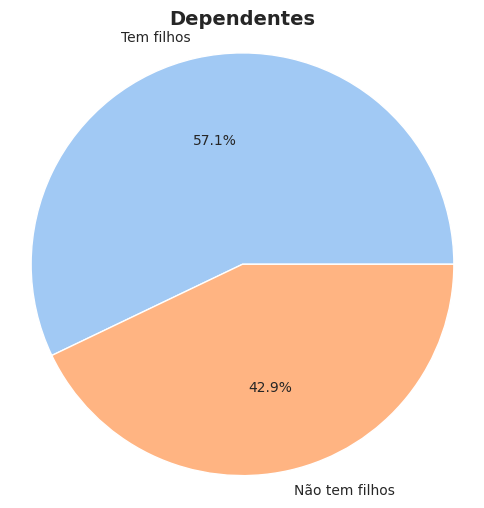

In [14]:
colors = sns.color_palette("pastel")

child_status = df['children'].apply(lambda x: 'Tem filhos' if x > 0 else 'Não tem filhos')

counts = child_status.value_counts()

plt.figure(figsize=(6, 6))

plt.pie(counts,
    labels=counts.index,
    autopct='%1.1f%%',
    colors=colors[:2],)

plt.title('Dependentes', fontsize=14, fontweight='bold')
plt.axis('equal')

plt.show()

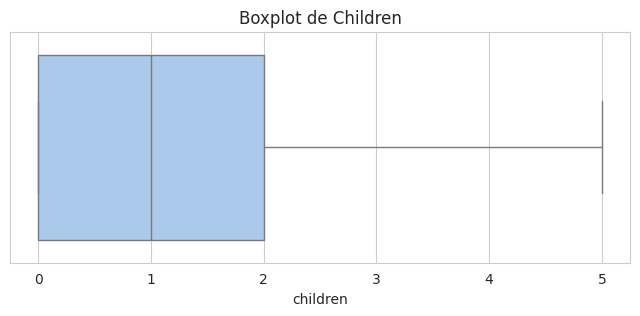

In [15]:
plt.figure(figsize=(8,3))
sns.boxplot(data=df, x='children', palette=colors)
plt.title('Boxplot de Children')
plt.show()

Relativamente ao número de dependentes, observa-se que a **maioria dos beneficiários (574 pessoas) não tem filhos** cobertos pelo seguro. À medida que o número de filhos aumenta, a frequência diminui drasticamente, sendo muito raro encontrar casos com 4 ou 5 filhos. No cômputo geral, 57,1% da amostra tem pelo menos um filho, enquanto 42,9% não tem dependentes.

### 3.2.5. `'smoker'`

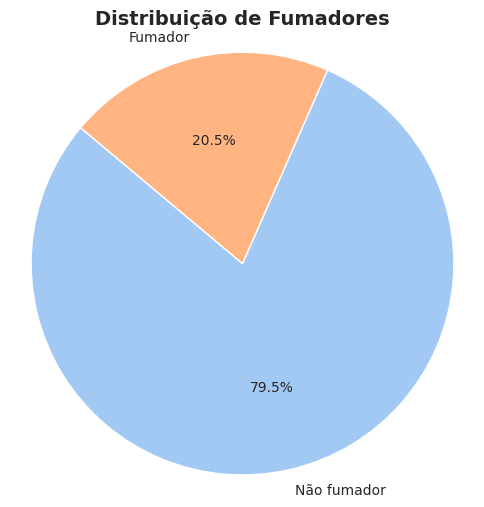

In [16]:
smoker_labels = df['smoker'].map({
    'yes': 'Fumador',
    'no': 'Não fumador'})

smoker_counts = smoker_labels.value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    smoker_counts,
    labels=smoker_counts.index,
    colors=colors[:2],
    autopct='%1.1f%%',
    startangle=140)

plt.title('Distribuição de Fumadores', fontsize=14, fontweight='bold')
plt.axis('equal')

plt.show()

A análise da variável de hábito tabágico revela uma **predominância significativa de não fumadores**, que constituem a grande maioria da amostra com **79,5% (1.064 indivíduos)**. Em contrapartida, os fumadores representam apenas **20,5% (274 indivíduos)** do dataset. Esta disparidade é um fator crucial para a análise de custos, uma vez que o hábito de fumar é frequentemente um dos preditores mais influentes no aumento das despesas de saúde.

### 3.2.6. `'region'`


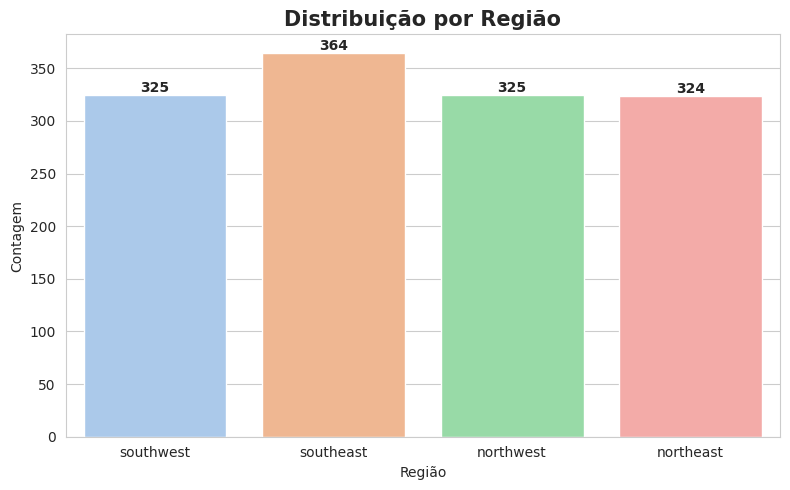

In [17]:
colors = sns.color_palette("pastel")

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='region',
    palette=colors)

plt.title('Distribuição por Região', fontsize=15, fontweight='bold')
plt.xlabel('Região')
plt.ylabel('Contagem')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height)}',
                (p.get_x() + p.get_width()/2, height),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

A distribuição geográfica dos beneficiários pelas quatro regiões dos EUA é **bastante uniforme**. A região Sudeste é a que apresenta uma frequência ligeiramente superior (364 registos), enquanto as restantes regiões (Sudoeste, Noroeste e Nordeste) apresentam valores quase idênticos entre si, situando-se nos 324-325 registos cada.

### 3.2.7. `'charges'`


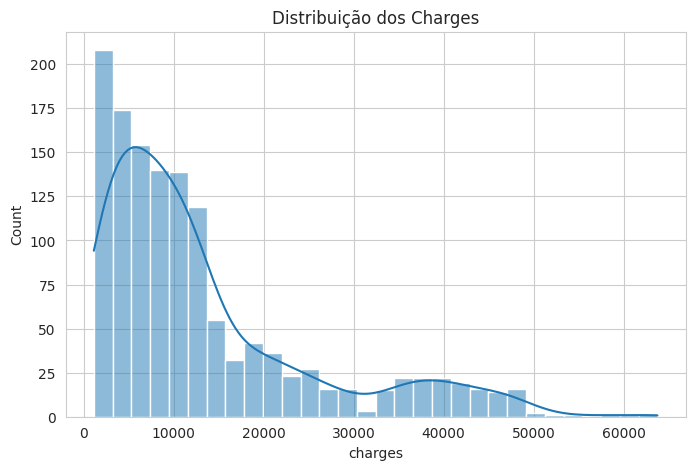

In [18]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='charges', kde=True, palette=colors)
plt.title('Distribuição dos Charges')
plt.show()

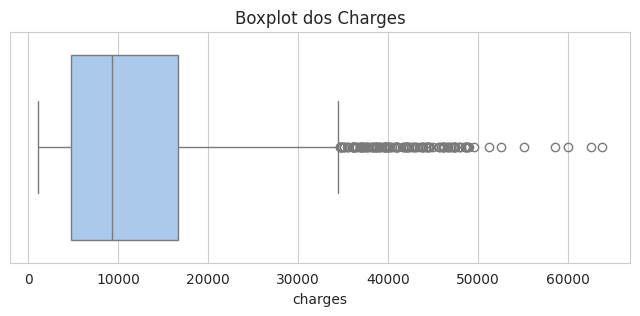

In [19]:
plt.figure(figsize=(8,3))
sns.boxplot(data=df, x='charges', palette=colors)
plt.title('Boxplot dos Charges')
plt.show()

A variável target `'charges'` exibe uma **distribuição fortemente enviesada à direita (*right-skewed*)**, indicando que a maioria dos beneficiários tem custos de saúde relativamente baixos, concentrados abaixo dos 15.000. Contudo, o boxplot destaca uma **quantidade significativa de outliers de alto valor**, com custos que chegam a ultrapassar os 60.000, o que explica o facto de a média ser consideravelmente superior à mediana.

## **3.3. Análise de correlação**

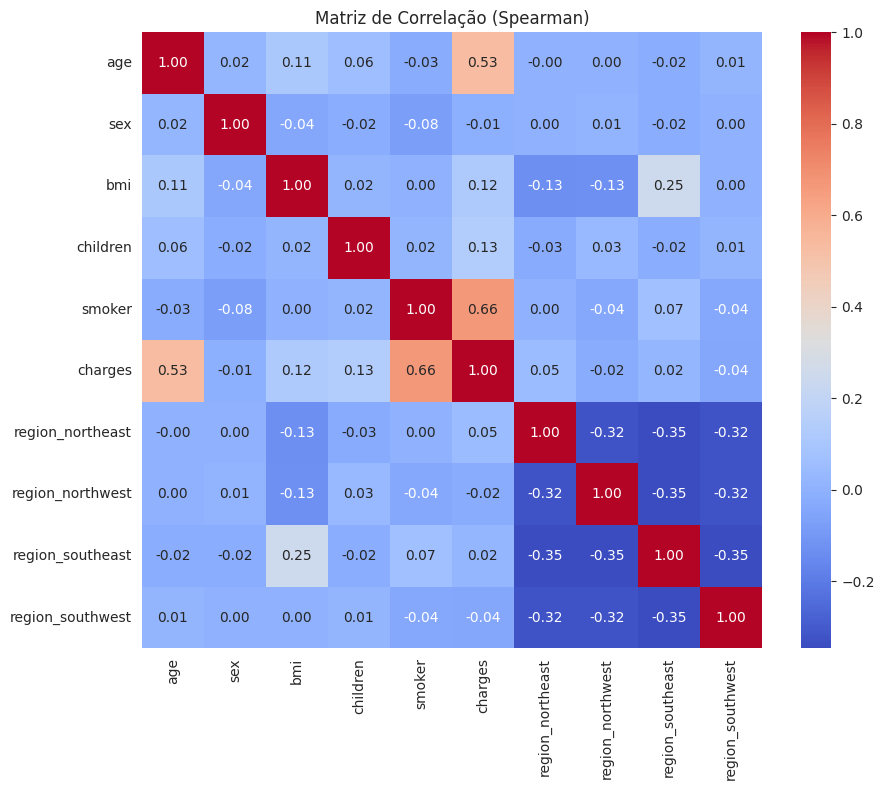

In [20]:
df_corr = df.copy()

# Encoding de variáveis catgóricas binárias
df_corr['sex'] = df_corr['sex'].map({'male': 0, 'female': 1})
df_corr['smoker'] = df_corr['smoker'].map({'no': 0, 'yes': 1})

# One-hot encoding para a variável categórica 'region'
df_corr = pd.get_dummies(df_corr, columns=['region'], drop_first=False)

# Matriz de correlação (Spearman) - Heatmap
corr_matrix = df_corr.corr(method='spearman')

plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Matriz de Correlação (Spearman)')
plt.show()

A matriz de correlação permite identificar a força e a direção das relações entre as variáveis. Através da observação do Heatmap, destacam-se os seguintes pontos:

- **Hábito tabágico (`'smoker'`):** Esta variável apresenta a **correlação positiva mais forte** com os custos de saúde (`'charges'`). Este resultado confirma as observações anteriores: o hábito de fumar é o preditor isolado com maior impacto no aumento das despesas médicas neste dataset.

- **Influência da Idade (`'age'`):** Verifica-se uma correlação moderada e positiva entre a idade e os custos. Como seria de esperar, à medida que a idade dos beneficiários aumenta, há uma tendência natural para o crescimento do valor cobrado pelo seguro, refletindo o aumento do risco de saúde associado ao envelhecimento.

- **Impacto do IMC (`'bmi'`):** O índice de massa corporal também exibe uma correlação positiva com a variável target. Embora a relação seja menos intensa do que a da idade, os dados sugerem que beneficiários com um IMC mais elevado (que, como vimos, constituem grande parte da amostra) tendem a enfrentar custos de seguro superiores.

- **Ausência de Multicolinearidade:** É muito positivo observar que as correlações entre as variáveis independentes (por exemplo, entre `'age'` e `'bmi'` ou entre `'children'` e `'smoker'`) são muito baixas. Isto indica que não existe multicolinearidade significativa, o que significa que cada variável fornece informações distintas ao modelo, facilitando a fase de modelação preditiva que se segue.


# **4. Avaliação da Qualidade dos Dados**

| _Tema_ | _Avaliação_ |
| :--- | :--- |
| _Volume vs suficiência_ | Consideramos o volume de 1338 registos pequeno, mas suficiente e adequado para a análise e modelação |
| _Missing Values_ | Não verificamos a presença de missing values em nenhuma das features |
| _Duplicados_ | Identificámos a presença de 1 registo duplicado |
| _Outliers_ | Não há presença relevante de outliers que prejudiquem o modelo |
| _Balanceamento de Classes_ | Não é aplicável, tendo em conta que é um problema de regressão |

***Nota** - *Outliers*: No boxplot da variável target `'charges'` verificamos a presença de um número considerável de *outliers*, porém decidimos não proceder ao seu tratamento (por exemplo através de *capping*) por tratar-se da coluna alvo.

# **5. Data Preparation**

### **5.1. Remoção de Duplicados**

Como avaliado no bloco 4., o único tratamento de dados necessário é eliminar a *row* duplicada do dataset.

In [21]:
df.drop_duplicates(inplace=True)

print(f"Duplicados: {df.duplicated().sum()}")

Duplicados: 0


### **5.2. Codificação de Variáveis Categóricas**

In [22]:
df_encoded = df.copy()

# 1. Label Encoding para variáveis binárias
df_encoded['sex'] = df_encoded['sex'].map({'male': 0, 'female': 1})
df_encoded['smoker'] = df_encoded['smoker'].map({'no': 0, 'yes': 1})

# 2. One-Hot Encoding para a variável categórica 'region'
df_encoded = pd.get_dummies(df_encoded, columns=['region'], drop_first=False, dtype=int)

print("Dataset após codificação:")
display(df_encoded.head())

print("\nColunas finais após encoding:")
print(list(df_encoded.columns))

Dataset após codificação:


,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,0,1
1,18,0,33.770,1,0,1725.55230,0,0,1,0
2,28,0,33.000,3,0,4449.46200,0,0,1,0
3,33,0,22.705,0,0,21984.47061,0,1,0,0
4,32,0,28.880,0,0,3866.85520,0,1,0,0



Colunas finais após encoding:
['age', 'sex', 'bmi', 'children', 'smoker', 'charges', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest']


### **5.3. Separação Treino e Teste**

In [23]:
# Separar features (X) e target (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Dimensões do Train/Test:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

Dimensões do Train/Test:
X_train: (1069, 9)
X_test : (268, 9)
y_train: (1069,)
y_test : (268,)


### **5.4. Normalização de Variáveis Numéricas**

Decidimos realizar a normalização das variáveis numéricas após separação de treino e teste de modo a evitar data leakage. Dado que técnicas de normalização calculam estatísticas como a média, desvio‑padrão ou valores mínimos e máximos, aplicá‑las antes do *split* faria com que o modelo aprendesse inadvertidamente informação proveniente dos dados de teste, comprometendo a validade da avaliação.

In [24]:
numeric_cols = ['age', 'bmi', 'children']

scaler = StandardScaler()

scaler.fit(X_train[numeric_cols]) # apenas aplicamos ao X_train

# Transformar treino e teste
X_train[numeric_cols] = scaler.transform(X_train[numeric_cols])
X_test[numeric_cols]  = scaler.transform(X_test[numeric_cols])

print("Normalização concluída. Exemplo das primeiras linhas normalizadas:")
display(X_train.head())

Normalização concluída. Exemplo das primeiras linhas normalizadas:


,age,sex,bmi,children,smoker,region_northeast,region_northwest,region_southeast,region_southwest
1114,-1.157680,0,-0.996928,-0.907908,0,1,0,0,0
968,-1.300619,0,-0.792762,0.766904,0,1,0,0,0
599,0.914926,1,1.154664,0.766904,0,0,1,0,0
170,1.701087,0,1.806837,-0.907908,0,0,0,1,0
275,0.557580,1,-0.651417,0.766904,0,1,0,0,0


### **5.5. Versão final das Variáveis**

| _Feature_ | _Tipo_ | _Preparação aplicada_ | _Descrição_ |
| :--- | :--- | :--- | :--- |
| _age_ | Numérica | StandardScaler | Idade do beneficiário |
| _sex_ | Categórica (binária) | LabelEncoder | Sexo do beneficiário |
| _bmi_ | Numérica | StandardScaler | Índice de massa corporal (idealmente 18.5 a 24.9) |
| _children_ | Numérica | StandardScaler | Número de filhos cobertos pelo seguro de saúde / Número de dependentes |
| _smoker_ | Categórica (binária) | LabelEncoder | Fumante ou não fumante |
| _region_northeast_ | Booleana | One-Hot Encoding | Área residencial do beneficiário nos Estados Unidos da América - nordeste |
| _region_northwest_ | Booleana | One-Hot Encoding | Área residencial do beneficiário nos Estados Unidos da América - noroeste |
| _region_southeast_ | Booleana | One-Hot Encoding | Área residencial do beneficiário nos Estados Unidos da América - sudeste |
| _region_southwest_ | Booleana | One-Hot Encoding | Área residencial do beneficiário nos Estados Unidos da América - sudoeste |
| _charges_ | Numérica | --- | Custo do seguro de saúde cobrado ao beneficiário (target) |

***Nota** - `'charges'`: aquando do desenvolvimento do bloco de modeling, podemos repensar a aplicação de uma técnica de preparação da coluna target ('charges') caso decidamos testar modelos que sejam sensíveis à sua escala, como SVR ou KNN Regression.

# **6. Modeling**

Selecionamos três algoritmos distintos:

**Linear Regression**

A Regressão Linear é um modelo estatístico simples que procura estabelecer uma relação linear entre as variáveis independentes e a variável alvo. Foi escolhida por servir como modelo de referência (baseline), permitindo comparar o desempenho de algoritmos mais avançados.

**Random Forest Regressor**

O Random Forest Regressor é um algoritmo baseado em múltiplas árvores de decisão. Este modelo consegue capturar relações não lineares entre as variáveis e tende a apresentar melhor desempenho em problemas de regressão com interações complexas entre atributos.

**XGBoost Regressor**

O XGBoost Regressor é um algoritmo de gradient boosting que constrói árvores de decisão de forma sequencial, em que cada nova árvore procura corrigir os erros cometidos pelas anteriores. Foi escolhido por combinar elevada capacidade preditiva com mecanismos de regularização que ajudam a reduzir o overfitting, sendo frequentemente um dos modelos mais competitivos em problemas de regressão com dados tabulares.



### **6.1. Construção dos modelos**

Começamos por treinar os modelos selecionados utilizando o conjunto de treino que preparamos acima.

In [25]:
# Linear Regression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Linear Regression treinado com sucesso.")

Linear Regression treinado com sucesso.


In [26]:
# Random Forest Regressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest treinado com sucesso.")

Random Forest treinado com sucesso.


In [27]:
#XGBoost Regression

xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)

print("XGBoost treinado com sucesso.")

XGBoost treinado com sucesso.


# **7. Avaliação dos modelos**

### **7.1. Métricas de Avaliação**

Para avaliar os modelos de regressão escolhemos as seguintes métricas:

- MAE (Mean Absolute Error)
- MSE (Mean Squared Error)
- RMSE (Root Mean Squared Error)
- R² (Coeficiente de Determinação)

Estas métricas permitem-nos analisar a capacidade preditiva dos modelos e comparar objetivamente o seu desempenho.

In [28]:
def evaluate_model(y_true, predictions):

    mae = mean_absolute_error(y_true, predictions)
    mse = mean_squared_error(y_true, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, predictions)

    return mae, mse, rmse, r2

In [29]:
lr_mae, lr_mse, lr_rmse, lr_r2 = evaluate_model(
    y_test,
    lr_predictions
)

print("LINEAR REGRESSION")
print(f"MAE  : {lr_mae:.2f}")
print(f"MSE  : {lr_mse:.2f}")
print(f"RMSE : {lr_rmse:.2f}")
print(f"R²   : {lr_r2:.4f}")

LINEAR REGRESSION
MAE  : 4177.05
MSE  : 35478020.68
RMSE : 5956.34
R²   : 0.8069


In [30]:
rf_mae, rf_mse, rf_rmse, rf_r2 = evaluate_model(
    y_test,
    rf_predictions
)

print("RANDOM FOREST")
print(f"MAE  : {rf_mae:.2f}")
print(f"MSE  : {rf_mse:.2f}")
print(f"RMSE : {rf_rmse:.2f}")
print(f"R²   : {rf_r2:.4f}")

RANDOM FOREST
MAE  : 2556.15
MSE  : 21630374.96
RMSE : 4650.85
R²   : 0.8823


In [31]:
xgb_mae, xgb_mse, xgb_rmse, xgb_r2 = evaluate_model(
    y_test,
    xgb_predictions
)

print("XGBOOST")
print(f"MAE  : {xgb_mae:.2f}")
print(f"MSE  : {xgb_mse:.2f}")
print(f"RMSE : {xgb_rmse:.2f}")
print(f"R²   : {xgb_r2:.4f}")

XGBOOST
MAE  : 2470.32
MSE  : 19987440.74
RMSE : 4470.73
R²   : 0.8912


### **7.2. Comparação dos Modelos**

In [32]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost'],
    'MAE': [lr_mae, rf_mae, xgb_mae],
    'MSE': [lr_mse, rf_mse, xgb_mse],
    'RMSE': [lr_rmse, rf_rmse, xgb_rmse],
    'R²': [lr_r2, rf_r2, xgb_r2]
})

results

,Model,MAE,MSE,RMSE,R²
0,Linear Regression,4177.045561,3.547802e+07,5956.342894,0.806929
1,Random Forest,2556.147390,2.163037e+07,4650.846693,0.882288
2,XGBoost,2470.322459,1.998744e+07,4470.731567,0.891228


In [33]:
best_model = results.loc[results['R²'].idxmax()]

print("Melhor Modelo:")
display(best_model)

Melhor Modelo:


Model            XGBoost
MAE          2470.322459
MSE      19987440.743926
RMSE         4470.731567
R²              0.891228
Name: 2, dtype: object

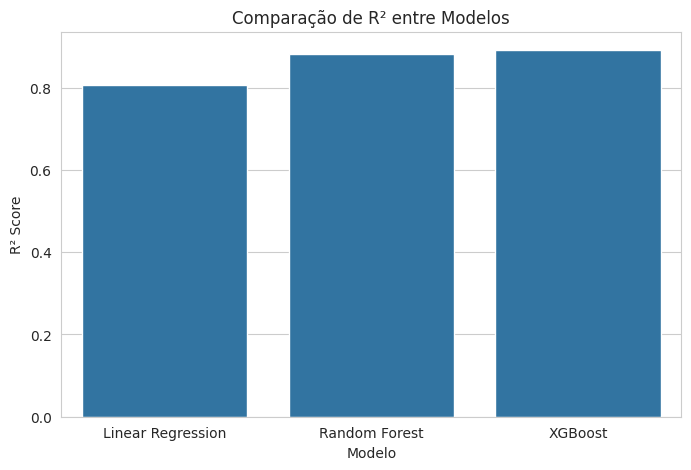

In [34]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x='Model',
    y='R²'
)

plt.title('Comparação de R² entre Modelos')
plt.ylabel('R² Score')
plt.xlabel('Modelo')

plt.show()

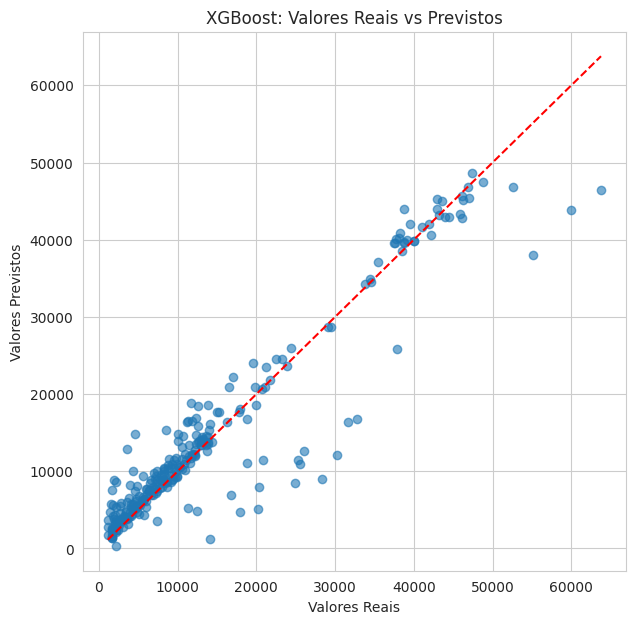

In [35]:
plt.figure(figsize=(7,7))

plt.scatter(
    y_test,
    xgb_predictions,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Valores Reais")
plt.ylabel("Valores Previstos")

plt.title("XGBoost: Valores Reais vs Previstos")

plt.show()

# **8. Conclusão**

Os resultados obtidos demonstram que os três modelos testados foram capazes de prever os custos dos seguros de saúde com um desempenho satisfatório, verificando-se uma melhoria clara à medida que se avança para algoritmos mais complexos.

A Regressão Linear, utilizada como modelo de referência (baseline), obteve o desempenho mais modesto **(R² ≈ 0,81)**, o que era expectável dada a sua incapacidade de captar relações não lineares. O Random Forest melhorou consideravelmente os resultados **(R² ≈ 0,88)**, mas foi o XGBoost que se destacou como o modelo mais eficaz **(R² ≈ 0,89; RMSE ≈ 4 471; MAE ≈ 2 470)**, apresentando o menor erro de previsão entre todos.

Este melhor desempenho do XGBoost pode ser explicado pelo seu mecanismo de gradient boosting, que constrói árvores de forma sequencial, corrigindo progressivamente os erros das anteriores. Esta abordagem, aliada aos mecanismos de regularização do algoritmo, permite modelar com maior precisão as relações não lineares e as interações entre variáveis como idade, índice de massa corporal e hábitos de tabagismofatores com impacto significativo no custo do seguro, superando ligeiramente o Random Forest e reduzindo o risco de overfitting.

Como limitações do estudo, destacamos a dimensão relativamente reduzida do dataset e a ausência de variáveis potencialmente relevantes, como histórico clínico ou nível de rendimento dos beneficiários.
De forma geral, a solução desenvolvida apresenta bom desempenho na previsão dos custos de seguros de saúde, sendo o XGBoost o modelo mais adequado entre os testados. Ainda assim, existe margem para melhoria através do ajuste de hiperparâmetros (por exemplo, via grid search ou cross-validation) e da inclusão de mais variáveis explicativas.

# **9. Deployment**

In [36]:
import warnings, requests, zipfile, io
warnings.simplefilter('ignore')
import pandas as pd
from scipy.io import arff

import os
import boto3
import sagemaker
from sagemaker.image_uris import retrieve
from sklearn.model_selection import train_test_split

In [37]:
session = sagemaker.Session()
bucket = session.default_bucket()
role = sagemaker.get_execution_role()
prefix = 'projeto-health-insurance'

train_df = pd.concat([y_train, X_train], axis=1)
test_df = pd.concat([y_test, X_test], axis=1)

test, validate = train_test_split(test_df, test_size=0.5, random_state=42)

train_file = 'insurance_train.csv'
test_file = 'insurance_test.csv'
validate_file = 'insurance_validate.csv'

s3_resource = boto3.Session().resource('s3')
def upload_s3_csv(filename, folder, dataframe):
    csv_buffer = io.StringIO()
    dataframe.to_csv(csv_buffer, header=False, index=False)
    s3_resource.Bucket(bucket).Object(os.path.join(prefix, folder, filename)).put(Body=csv_buffer.getvalue())

upload_s3_csv(train_file, 'train', train_df)
upload_s3_csv(test_file, 'test', test)
upload_s3_csv(validate_file, 'validate', validate)

container = sagemaker.image_uris.retrieve('xgboost', boto3.Session().region_name, '1.0-1')

# Hiperparâmetros baseados no melhor modelo (R² 0.89) [1, 2]
hyperparams = {
    "num_round": "100",             
    "eval_metric": "rmse",          
    "objective": "reg:squarederror",
    "max_depth": "6",               
    "eta": "0.1"}                    

s3_output_location = "s3://{}/{}/output/".format(bucket, prefix)

xgb_model = sagemaker.estimator.Estimator(
    container,
    role,
    instance_count=1,
    instance_type='ml.m4.xlarge',
    output_path=s3_output_location,
    hyperparameters=hyperparams,
    sagemaker_session=session
)

train_channel = sagemaker.inputs.TrainingInput(
    "s3://{}/{}/train/".format(bucket, prefix),
    content_type='text/csv')

validate_channel =sagemaker.inputs.TrainingInput(
    "s3://{}/{}/validate/".format(bucket, prefix),
    content_type='text/csv')

data_channels = {'train': train_channel, 'validation': validate_channel}

xgb_model.fit(inputs=data_channels, logs=True)

print('ready for hosting!')

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml


INFO:sagemaker:Creating training-job with name: sagemaker-xgboost-2026-06-02-17-57-18-939


2026-06-02 17:57:19 Starting - Starting the training job...
2026-06-02 17:57:35 Starting - Preparing the instances for training...
2026-06-02 17:58:05 Downloading - Downloading input data.........
2026-06-02 17:59:26 Training - Training image download completed. Training in progress....
2026-06-02 18:00:05 Uploading - Uploading generated training model
2026-06-02 18:00:05 Completed - Training job completed
..Training seconds: 119
Billable seconds: 119
ready for hosting!


### **9.1. Hosting the Model**

In [38]:
xgb_predictor = xgb_model.deploy(initial_instance_count=1,
                serializer = sagemaker.serializers.CSVSerializer(),
                instance_type='ml.m4.xlarge')

INFO:sagemaker:Creating model with name: sagemaker-xgboost-2026-06-02-18-00-30-745
INFO:sagemaker:Creating endpoint-config with name sagemaker-xgboost-2026-06-02-18-00-30-745
INFO:sagemaker:Creating endpoint with name sagemaker-xgboost-2026-06-02-18-00-30-745


-------!

### **9.2. Performing Predictions**

In [39]:
# Recordar a estrutura do conjunto de teste
# (a 1.ª coluna corresponde sempre à target 'charges')
print("Dimensoes do conjunto de teste:", test.shape)
display(test.head(5))

# Selecionar a 1.a linha SEM a coluna target -> apenas as features
# iloc[linhas, colunas]: 0:1 = primeira linha | 1: = todas as colunas exceto a target
row = test.iloc[0:1, 1:]

# Converter essa linha para CSV (sem cabecalho nem indice) e guardar num buffer de texto
batch_X_csv_buffer = io.StringIO()
row.to_csv(batch_X_csv_buffer, header=False, index=False)
test_row = batch_X_csv_buffer.getvalue()

# Efetuar a previsao.
# Ao contrario do exemplo de classificacao (que devolve uma probabilidade),
# o nosso modelo de regressao devolve diretamente o custo previsto do seguro.
prediction = xgb_predictor.predict(test_row).decode("utf-8").strip()
predicted_charge = float(prediction)

# Comparar com o valor real (1.a coluna = charges)
actual_charge = test.iloc[0, 0]

print(f"\nCusto previsto : {predicted_charge:,.2f}")
print(f"Custo real     : {actual_charge:,.2f}")
print(f"Erro absoluto  : {abs(predicted_charge - actual_charge):,.2f}")

Dimensoes do conjunto de teste: (134, 10)


,charges,age,sex,bmi,children,smoker,region_northeast,region_northwest,region_southeast,region_southwest
896,19798.05455,0.271703,1,-1.735065,0.766904,1,1,0,0,0
1171,22478.60000,0.271703,1,-0.634885,0.766904,1,0,0,0,1
979,4889.03680,-0.228581,1,-0.102566,-0.907908,0,0,0,1,0
629,42983.45850,0.343172,1,1.390240,-0.907908,1,0,1,0,0
1323,43896.37630,0.200234,1,1.624989,0.766904,1,0,0,1,0



Custo previsto : 21,451.39
Custo real     : 19,798.05
Erro absoluto  : 1,653.34


### **9.3. Terminating the deployed model**

In [40]:
xgb_predictor.delete_endpoint(delete_endpoint_config=True)

INFO:sagemaker:Deleting endpoint configuration with name: sagemaker-xgboost-2026-06-02-18-00-30-745
INFO:sagemaker:Deleting endpoint with name: sagemaker-xgboost-2026-06-02-18-00-30-745


### **9.4. Performing a Batch Transform**

Em vez de fazer previsões linha a linha, podemos usar o *batch transform* do SageMaker para prever todo o conjunto de teste de uma só vez. O SageMaker lança uma instância com o modelo, executa as previsões sobre todos os registos, escreve os resultados no Amazon S3 e termina automaticamente a instância.

Começamos por isolar todas as linhas do conjunto de teste, excluindo apenas a coluna target (`charges`).

In [41]:
# Todas as linhas, todas as colunas EXCETO a target (1.a coluna)
batch_X = test.iloc[:, 1:]
batch_X.head()

,age,sex,bmi,children,smoker,region_northeast,region_northwest,region_southeast,region_southwest
896,0.271703,1,-1.735065,0.766904,1,1,0,0,0
1171,0.271703,1,-0.634885,0.766904,1,0,0,0,1
979,-0.228581,1,-0.102566,-0.907908,0,0,0,1,0
629,0.343172,1,1.390240,-0.907908,1,0,1,0,0
1323,0.200234,1,1.624989,0.766904,1,0,0,1,0


De seguida, escrevemos estes dados para um ficheiro CSV no Amazon S3.

In [42]:
batch_X_file = 'batch-in.csv'
upload_s3_csv(batch_X_file, 'batch-in', batch_X)

Por fim, antes de executar a transformação, configuramos o *transformer* com o ficheiro de input, a localização de output e o tipo de instância.

In [43]:
batch_output = "s3://{}/{}/batch-out/".format(bucket, prefix)
batch_input  = "s3://{}/{}/batch-in/{}".format(bucket, prefix, batch_X_file)

xgb_transformer = xgb_model.transformer(
    instance_count=1,
    instance_type='ml.m4.xlarge',
    strategy='MultiRecord',
    assemble_with='Line',
    output_path=batch_output)

xgb_transformer.transform(
    data=batch_input,
    data_type='S3Prefix',
    content_type='text/csv',
    split_type='Line')

xgb_transformer.wait()

INFO:sagemaker:Creating model with name: sagemaker-xgboost-2026-06-02-18-04-34-177
INFO:sagemaker:Creating transform job with name: sagemaker-xgboost-2026-06-02-18-04-34-750


.......................................
...

Concluída a transformação, descarregamos os resultados do Amazon S3 e comparamos as previsões com os valores reais.

Note-se que, por se tratar de um problema de **regressão**, o modelo devolve diretamente o custo previsto. Não é necessário aplicar qualquer *threshold* para converter em 0/1 (como aconteceria num problema de classificação); em vez disso, comparamos os valores previstos com os reais e calculamos as métricas de regressão.

In [44]:
s3 = boto3.client('s3')
obj = s3.get_object(Bucket=bucket, Key="{}/batch-out/{}".format(prefix, 'batch-in.csv.out'))
target_predicted = pd.read_csv(io.BytesIO(obj['Body'].read()), sep=',', names=['charges_previsto'])

# Comparacao lado a lado: previsto vs real
comparison = target_predicted.copy()
comparison['charges_real']  = test.iloc[:, 0].values
comparison['erro_absoluto'] = (comparison['charges_real'] - comparison['charges_previsto']).abs()
display(comparison.head(10))

# Metricas de regressao sobre todo o conjunto de teste
mae  = mean_absolute_error(comparison['charges_real'], comparison['charges_previsto'])
rmse = np.sqrt(mean_squared_error(comparison['charges_real'], comparison['charges_previsto']))
r2   = r2_score(comparison['charges_real'], comparison['charges_previsto'])

print("BATCH TRANSFORM - XGBoost (SageMaker)")
print(f"MAE  : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R2   : {r2:.4f}")

,charges_previsto,charges_real,erro_absoluto
0,21451.394531,19798.05455,1653.339981
1,24166.056641,22478.60000,1687.456641
2,4697.064453,4889.03680,191.972347
3,44948.191406,42983.45850,1964.732906
4,43186.027344,43896.37630,710.348956
5,14010.548828,12949.15540,1061.393428
6,4098.283203,4137.52270,39.239497
7,8156.994141,8688.85885,531.864709
8,45944.835938,46200.98510,256.149162
9,13834.625000,13880.94900,46.324000


BATCH TRANSFORM - XGBoost (SageMaker)
MAE  : 2,539.82
RMSE : 4,452.64
R2   : 0.8931
